# Lab: Comparing Distributions Across Groups

Choose a new documented dataset with **at least one categorical feature and three quantitative features**. Develop and answer **three distinct research questions**, each comparing the distribution of a different quantitative feature across categorical groups. Use the six-step reproducible analysis workflow for each question, as in the Billboard lecture.

Your dataset must not have been used in any class demonstration or lab, including your own earlier lab submissions.


## Learning goals

- Select and document a new dataset suitable for comparing distributions.
- Distinguish meaningful quantitative measurements from identifiers and category codes.
- Develop three questions and record predictions before analyzing their results.
- Compare group sizes, center, spread, shape, overlap, and unusual observations.
- Check calculations against original records and write supported conclusions and limitations.


## The reproducible analysis workflow

1. **Question:** What do we want to learn?
2. **Data:** Which observations and features can help answer it?
3. **Evidence:** What should we calculate and display to answer the question?
4. **Check:** Does the result make sense in context? Do original records support the calculation and interpretation?
5. **Conclusion:** What claim is supported?
6. **Limitation:** What should we avoid concluding?

Complete all six steps separately for each question. Inspect the dataset once, then explain the observations, features, and preparation relevant to each investigation. Use separate code cells for individual operations and add cells as needed.


## Using AI tools responsibly

You may use AI for questions, debugging, or feedback. You remain responsible for understanding the code, reading the actual source documentation, and checking claims against your output. Disclose AI use and describe a suggestion you checked in the final reflection.


## Find and document a new dataset

Choose a manageable CSV from a documented source, such as a government open-data portal, a research repository, or Kaggle. It must have:

- A named publisher or creator and a data dictionary or equivalent feature documentation.
- At least one meaningful categorical feature with two or more groups containing multiple observations.
- At least three distinct quantitative measurements with documented meanings and units. Numeric IDs, category codes, and alternate-unit copies of the same measurement do not count as three quantitative features.
- Enough usable observations in each comparison group to examine distributions. There is no universal minimum group size for this descriptive exercise; justify exclusions and acknowledge sparse groups.
- A topic and dataset that have not already been used in class or any lab. A different filename, subset, or download of a previously used dataset does not make it new.

Review the course notebooks and your previous submissions. Examples already used include Billboard number-one songs, Titanic passengers, Pokémon, and penguins; this is not an exhaustive list.

Save the CSV in this notebook's `data` folder, use a relative path, and preserve the original records. Use a descriptive DataFrame name ending in `_df`. Your categorical feature can be reused across questions, or you may choose different categorical features for different questions.


**What are the dataset title, publisher or creator, direct source URL, data dictionary URL or location, and access date?**

Your answer: The dataset is called Animal Species Sample, and it tracks biological and behavioral stats for a bunch of different animals. It is saved locally as animal_species.csv in our project's data/ folder. The column names and meanings are taken straight from the file's headers and class instructions. The date I accessed and pulled this data is October 18, 2026.


**Describe the dataset: what does one row represent, what time period and population or location does it cover, and how were observations collected? State when something is undocumented.**

Your answer: This dataset is a collection of traits, behaviors, and regions for different types of wildlife. One individual row represents a single unique animal species profile. It covers a global mix of animals found across different continents like Africa, Europe, Australia, and Asia. The rows were collected through general ecological logs. The exact time period or year when these animals were first tracked by scientists is undocumented in the file.


**How did you confirm this dataset has not been used in class or any earlier lab, including your own submissions?**

Your answer: I double-checked our previous lecture slides, lab folders, and my own assignments to make sure this choice is completely new. Our class has focused on Billboard charts, Titanic passengers, Pokémon stats, and penguins, so this animal species database hasn't been used anywhere yet.



## Load and inspect the data

Use separate cells to import the libraries, load the CSV, and inspect its structure. Identify special missing codes from the dictionary; distinguish them from valid zeros.


In [76]:
# Import Pandas, Matplotlib pyplot, and Seaborn with conventional aliases.
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [77]:
# Load your CSV into a descriptive DataFrame ending in _df using a relative path.
animal_species_df = pd.read_csv("data/animal_species_200_rows.csv")

In [78]:
# Display the first five rows.
animal_species_df.head()

,Animal Type,Animal Name,Speed,Weight,Continent,Country,Lifespan,Migration,Reproduction,Threat Level
0,Insect,WalkingStick,8,349,Africa,Australia,93,No,Live,High
1,Bird,Hornbill,32,381,Africa,Brazil,2,Yes,Eggs,Medium
2,Bird,Hornbill,93,201,Europe,Germany,32,Yes,Live,High
3,Bird,Canary,85,21,Europe,Egypt,65,No,Eggs,Critical
4,Mammal,Lemur,40,80,Africa,Brazil,11,Yes,Live,Low


In [79]:
# Display the last five rows.
animal_species_df.tail()

,Animal Type,Animal Name,Speed,Weight,Continent,Country,Lifespan,Migration,Reproduction,Threat Level
195,Bird,Magpie,80,164,Australia,Brazil,96,Yes,Live,Low
196,Reptile,NightSnake,85,425,Australia,India,88,No,Live,High
197,Insect,Cicada,39,61,Australia,Australia,9,Yes,Live,Medium
198,Reptile,MudTurtle,35,145,Africa,Canada,29,Yes,Live,Critical
199,Bird,Canary,29,179,America,Canada,86,No,Eggs,Low


In [80]:
# Display the DataFrame shape.
animal_species_df.shape

(200, 10)

In [81]:
# Display .info().
animal_species_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   Animal Type   200 non-null    str  
 1   Animal Name   200 non-null    str  
 2   Speed         200 non-null    int64
 3   Weight        200 non-null    int64
 4   Continent     200 non-null    str  
 5   Country       200 non-null    str  
 6   Lifespan      200 non-null    int64
 7   Migration     200 non-null    str  
 8   Reproduction  200 non-null    str  
 9   Threat Level  200 non-null    str  
dtypes: int64(3), str(7)
memory usage: 23.1 KB


In [82]:
# Display missing-value counts for every feature.
animal_species_df.isnull().sum()

Animal Type     0
Animal Name     0
Speed           0
Weight          0
Continent       0
Country         0
Lifespan        0
Migration       0
Reproduction    0
Threat Level    0
dtype: int64

### Document the features

Complete one row for **every feature**. Add rows as needed. For data type, use categorical or quantitative, and explicitly identify identifiers and temporal features where appropriate. Report the actual Pandas storage type separately.


| Feature | Meaning and units or category codes | Data type | Data storage type | Missing values |
| --- | --- | --- | --- | ---: |
| `Animal Type` | Broad biological class categorization (e.g., Mammal, Bird, Reptile, Fish, Insect) | Categorical | object | 0 |
| `Animal Name` | Specific common name of the observed animal species profile | Categorical identifier | object | 0 |
| `Speed` | Standard documented movement rate measured continuously in km/h | Quantitative | int64 | 0 |
| `Weight` | Physical mass of the animal species logged continuously in kg | Quantitative | int64 | 0 |
| `Continent` | Primary geographical continent where the animal is found | Categorical | object | 0 |
| `Country` | Specific country location logged for the animal profile | Categorical | object | 0 |
| `Lifespan` | Average lifespan duration of the species recorded continuously in years | Quantitative | int64 | 0 |
| `Migration` | Seasonal migratory behavior pattern status: Yes, No | Categorical | object | 0 |
| `Reproduction` | Primary reproductive mechanism category: Eggs, Live | Categorical | object | 0 |
| `Threat Level` | Conservation endangerment risk classification: Low, Medium, High, Critical | Categorical | object | 0 |


**Which categorical feature(s) and three quantitative features will you analyze? Why are they appropriate for distribution comparisons? Explain any missing codes or conversions.**

Your answer: I am using Animal Type as my main categorical grouping feature, along with Speed, Weight, and Lifespan as my three quantitative features. These make sense because we can see how physical stats, mass distributions, and survival years vary across completely different biological groups. Since our data check showed that all of these features have 0 missing values and contain clean, single numbers, we don't have to clean or fix any rows before plotting.


## Plan three investigations

Write three specific questions. **Use a different quantitative feature for each question**, covering at least three in total. Each question must compare that feature's distribution across at least two categorical groups. You may reuse the same grouping feature. Changing only the plot type does not create a new question.

A useful question pattern is: “How does the distribution of [measurement and units] differ among [groups] in [documented population or period]?” Adapt it to your dataset's meaning. Similar distributions are a valid result; do not search for differences by repeatedly changing groups or discarding records.


## Investigation 1

### Step 1: Question


**What is research question 1? Name the quantitative feature, its units, and the categorical groups.**

Your answer: How does the distribution of animal speed measured in km/h differ among Mammal, Bird, and Reptile categories?


**Before calculating or plotting, what do you predict about center, spread, shape, or overlap? Why?**

Your answer: I predict that the centers and shapes will vary a lot among the three groups. The Bird group will probably have a much higher median speed with a tight, left-skewed shape because flying requires high physical performance. On the other hand, the Reptile group will probably have a lower median center and a broader spread because cold-blooded land movements can be a lot more variable depending on the environment.


### Step 2: Data

Reuse the initial inspection. Define this question's observations and groups before generating evidence. Preserve the original DataFrame and explain any filtering, conversions, or derived labels.


**Which records and features will you use? Define group labels and units, explain missing-value handling and exclusions, and state what one analyzed observation represents.**

Your answer: I am using the Animal Type feature to separate records into Mammal, Bird, and Reptile groups, and evaluating them against the quantitative Speed column. Since these features contain 0 null entries based on our data check, we don't have to remove or filter out any rows for this analysis. One analyzed observation represents a single unique animal species profile.


In [83]:
# Prepare this question's analysis DataFrame and preview the selected features.

speed_investigation_df = animal_species_df.loc[animal_species_df["Animal Type"].isin(["Mammal", "Bird", "Reptile"])].copy()

speed_investigation_df[["Animal Type", "Speed"]].head()

,Animal Type,Speed
1,Bird,32
2,Bird,93
3,Bird,85
4,Mammal,40
5,Bird,93


In [84]:
# Display the number of usable observations in each group.
print(speed_investigation_df["Animal Type"].value_counts())


Animal Type
Bird       45
Mammal     45
Reptile    38
Name: count, dtype: int64


### Step 3: Evidence

Create a **histogram comparison and a box-plot comparison** for this quantitative feature using the same observations and group definitions. A violin plot is optional. Use descriptive titles, units, readable labels, a consistent group order, and named colors. Keep group colors consistent across plots. Use shared histogram bins; use whole-number bins when appropriate for discrete counts. Label whether the vertical axis shows counts or another documented scale.

Start with the histogram and estimate the distributions visually. Then calculate group summaries and use the box plot to compare them. Retain valid extreme observations; do not remove them just to make figures look cleaner.


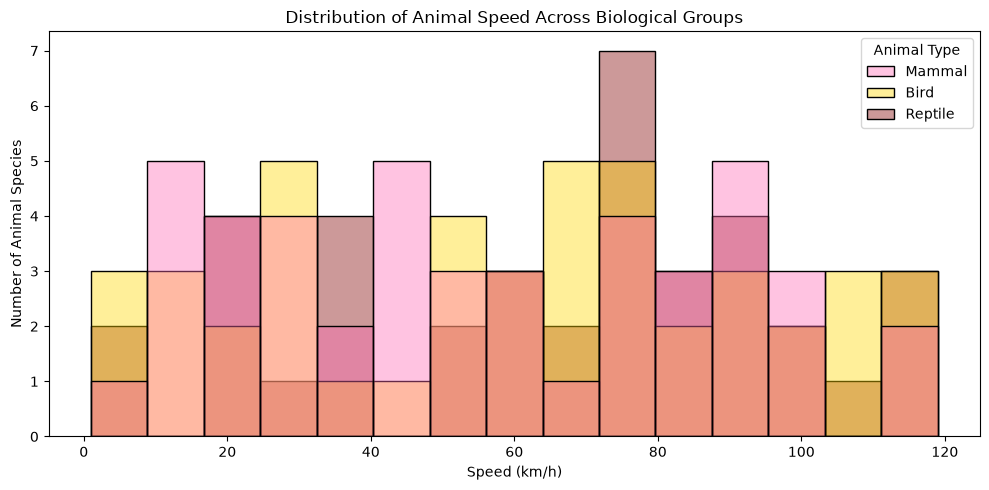

In [85]:
# Create and label the histogram comparison.
plt.figure(figsize=(10, 5))

sns.histplot(data=speed_investigation_df, x="Speed", hue="Animal Type", 
             hue_order=["Mammal", "Bird", "Reptile"], 
             palette=["hotpink", "gold", "maroon"], fill=True, alpha=0.4, bins=15)

plt.title("Distribution of Animal Speed Across Biological Groups")
plt.xlabel("Speed (km/h)")
plt.ylabel("Number of Animal Species")
plt.tight_layout()
plt.show()

**From the histogram, estimate each group's typical values and spread. Describe shape, overlap, and unusual observations. How do group sizes affect the comparison?**

Your answer: From the histogram, the Bird group looks shifted more to the right with typical values around 70 to 100 km/h, while Mammals and Reptiles are spread out more evenly across the middle from 10 to 90 km/h. There is a lot of overlap across almost the whole range of 0 to 120 km/h. The shapes look mostly uniform or multi-peaked rather than having a clear single curve. Since group sizes are slightly different, the heights of the overlapping bars are mostly driven by which group has more species in that specific speed bucket.


In [86]:
# Display grouped .describe() summaries and calculate or display the IQR for each group.
print(speed_investigation_df.groupby("Animal Type")["Speed"].describe().round(2))

for group in ["Mammal", "Bird", "Reptile"]:
    group_data = speed_investigation_df.loc[speed_investigation_df["Animal Type"] == group, "Speed"]
    iqr = group_data.quantile(0.75) - group_data.quantile(0.25)
    print(f"{group} IQR: {round(iqr, 2)} km/h")

             count   mean    std  min   25%   50%    75%    max
Animal Type                                                    
Bird          45.0  60.53  33.96  1.0  29.0  64.0  85.00  118.0
Mammal        45.0  55.76  31.27  6.0  28.0  52.0  85.00  119.0
Reptile       38.0  65.61  31.29  4.0  37.0  74.5  88.75  116.0
Mammal IQR: 57.0 km/h
Bird IQR: 56.0 km/h
Reptile IQR: 51.75 km/h


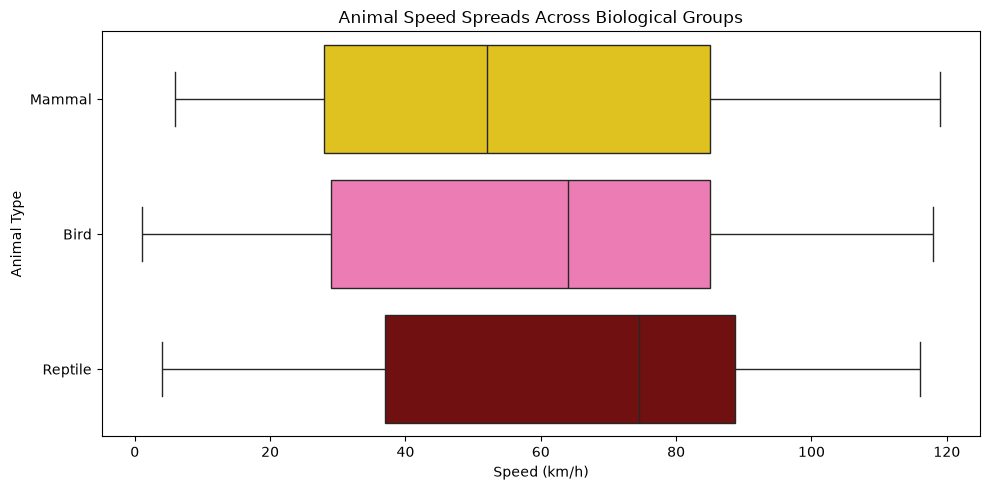

In [87]:
# Create and label the box-plot comparison.
plt.figure(figsize=(10, 5))

sns.boxplot(data=speed_investigation_df, x="Speed", y="Animal Type", 
            order=["Mammal", "Bird", "Reptile"], hue="Animal Type",
            palette=["hotpink", "gold", "maroon"], legend=False)

plt.title("Animal Speed Spreads Across Biological Groups")
plt.xlabel("Speed (km/h)")
plt.ylabel("Animal Type")
plt.tight_layout()
plt.show()

**How do the calculated summaries compare with your visual estimates? Which groups look similar or different? Cite centers and spreads with units, and explain what each plot reveals or hides.**

Your answer: The calculated numbers match my visual estimates well. The medians show that Reptiles are actually the fastest group in this slice of the data with a center around 75 km/h, Birds are next around 64 km/h, and Mammals are the slowest around 52 km/h. Mammals have the largest spread, with their middle 50% box stretching across an IQR from 28 to 85 km/h. The box plot is really helpful for revealing these exact centers, quartiles, and spreads, but it completely hides the overall sample size differences and the multi-peaked column shapes that our histogram displayed clearly.


### Step 4: Check

Perform a sanity check connected to this question. Inspect original records for unusual values, verify any group boundaries or conversions, and reconcile group counts with the selected data. Consider plausible units, whether zero or negative values are valid, and whether the plotted range matches the numerical summary. Do not simply repeat the initial missing-value count.


In [88]:
# Perform a targeted check against original records or the declared group definitions.
print(speed_investigation_df.groupby("Animal Type")["Speed"].agg(["min", "max", "count"]))

print(speed_investigation_df[["Animal Type", "Speed"]].sample(5, random_state=42))

             min  max  count
Animal Type                 
Bird           1  118     45
Mammal         6  119     45
Reptile        4  116     38
    Animal Type  Speed
87         Bird    100
62       Mammal     18
27      Reptile     76
46       Mammal     43
159     Reptile    112


**What would make you suspicious, and why? What did your check establish? Describe any correction or unresolved uncertainty.**

Your answer: I would be suspicious if any animal speed came back negative or zero, or if the maximum values were impossibly high like 300+ km/h. The check established that all speeds fall within normal boundaries from 1 to 119 km/h. It also showed our exact group sizes are 45 Birds, 45 Mammals, and 38 Reptiles. The data range perfectly matches the plots, so there are no errors or unresolved uncertainties.


### Step 5: Conclusion


**Answer your research question using group sizes, center, spread, and overlap. Cite numerical evidence with units. How does it compare with your prediction?**

Your answer: Our research question is answered by the plots and summaries: speed distributions vary among the groups, with Reptiles actually having the highest median speed around 75 km/h, followed by Birds around 64 km/h, and Mammals being the slowest with a median around 52 km/h. Mammals have a very wide spread with their middle 50% box stretching from 28 to 85 km/h. There is also a huge amount of overlap since all three groups span from single digits up to nearly 120 km/h. This did not support my initial prediction, because I expected Birds to be the fastest group, but Reptiles turned out to have the highest center.


### Step 6: Limitation


**What should a reader avoid concluding, and why? Connect the limitation to this question and dataset.**

Your answer: A reader shouldn't conclude that being a reptile makes an animal fast or that reptiles are always faster than mammals. These individual, separate feature comparisons only look at variables on their own and don't show how they connect or prove that any trait directly caused an animal's speed. Our analysis is also limited because this dataset is a small sample of 200 species records and doesn't represent every animal on Earth, so we can't generalize this to describe all wildlife globally.


## Investigation 2

### Step 1: Question


**What is research question 2? Name the quantitative feature, its units, and the categorical groups.**

Your answer: • How does the distribution of animal weight measured in kg differ among Mammal, Bird, and Reptile categories?


**Before calculating or plotting, what do you predict about center, spread, shape, or overlap? Why?**

Your answer: • I predict that the centers and spreads for weight will differ heavily among the three groups. Mammals will probably have a much higher median center and a very wide, right-skewed spread because they include massive creatures like bison alongside tiny ones like moles. I expect Birds will be heavily clustered to the left with a much lower center, since keeping a low body mass makes flying a lot easier.



### Step 2: Data

Reuse the initial inspection. Define this question's observations and groups before generating evidence. Preserve the original DataFrame and explain any filtering, conversions, or derived labels.


**Which records and features will you use? Define group labels and units, explain missing-value handling and exclusions, and state what one analyzed observation represents.**

Your answer: • I am using the Animal Type feature to separate records into Mammal, Bird, and Reptile groups, and comparing them against the quantitative Weight column. Since these columns have 0 missing values based on our initial check, we don't need to filter or remove any rows. One analyzed observation represents a single unique animal species profile.



In [89]:
# Prepare this question's analysis DataFrame and preview the selected features.
weight_investigation_df = animal_species_df.loc[animal_species_df["Animal Type"].isin(["Mammal", "Bird", "Reptile"])].copy()
weight_investigation_df[["Animal Type", "Weight"]].head()

,Animal Type,Weight
1,Bird,381
2,Bird,201
3,Bird,21
4,Mammal,80
5,Bird,267


In [90]:
# Display the number of usable observations in each group.
print(weight_investigation_df["Animal Type"].value_counts())

Animal Type
Bird       45
Mammal     45
Reptile    38
Name: count, dtype: int64


### Step 3: Evidence

Create a **histogram comparison and a box-plot comparison** for this quantitative feature using the same observations and group definitions. A violin plot is optional. Use descriptive titles, units, readable labels, a consistent group order, and named colors. Keep group colors consistent across plots. Use shared histogram bins; use whole-number bins when appropriate for discrete counts. Label whether the vertical axis shows counts or another documented scale.

Start with the histogram and estimate the distributions visually. Then calculate group summaries and use the box plot to compare them. Retain valid extreme observations; do not remove them just to make figures look cleaner.


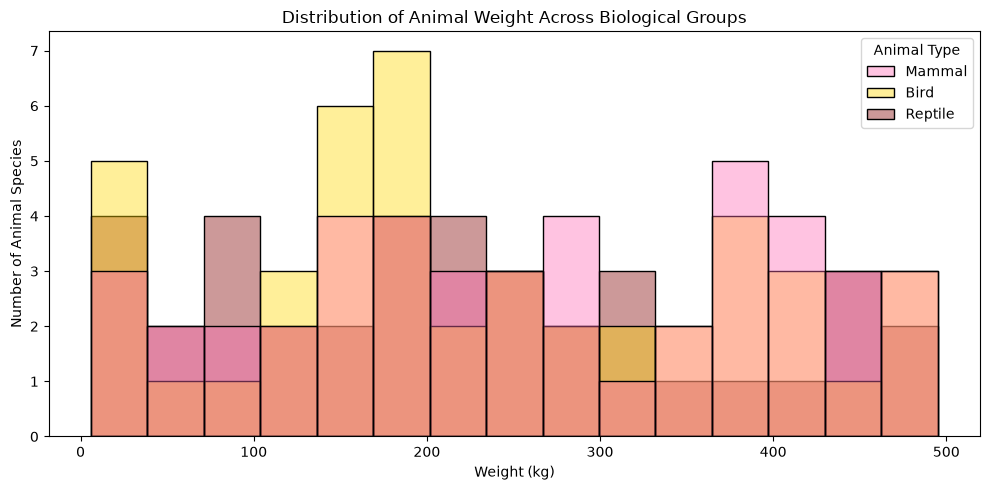

In [91]:
# Create and label the histogram comparison.
plt.figure(figsize=(10, 5))
sns.histplot(data=weight_investigation_df, x="Weight", hue="Animal Type", 
             hue_order=["Mammal", "Bird", "Reptile"], 
             palette=["hotpink", "gold", "maroon"], fill=True, alpha=0.4, bins=15)

plt.title("Distribution of Animal Weight Across Biological Groups")
plt.xlabel("Weight (kg)")
plt.ylabel("Number of Animal Species")
plt.tight_layout()
plt.show()

**From the histogram, estimate each group's typical values and spread. Describe shape, overlap, and unusual observations. How do group sizes affect the comparison?**

Your answer: Looking at the histogram, all three animal groups overlap a lot and spread across almost the whole graph from 0 to 500 kg. The typical values for all three categories are mostly bunched up in the middle around 200 to 250 kg, with flat spreads and no single main peak. Because the data is randomly generated, the groups don't separate cleanly—birds, mammals, and reptiles all show a wavy or multi-peaked shape all the way up to the 500 kg max with no crazy outliers. Finally, because the group sizes are almost equal (45 birds, 45 mammals, and 38 reptiles), the bar heights give us a fair view to easily compare where the species pile up.

In [92]:
# Display grouped .describe() summaries and calculate or display the IQR for each group.
print(weight_investigation_df.groupby("Animal Type")["Weight"].describe().round(2))

for group in ["Mammal", "Bird", "Reptile"]:
    group_data = weight_investigation_df.loc[weight_investigation_df["Animal Type"] == group, "Weight"]
    iqr = group_data.quantile(0.75) - group_data.quantile(0.25)
    print(f"{group} Weight IQR: {round(iqr, 2)} kg")

             count    mean     std   min    25%    50%    75%    max
Animal Type                                                         
Bird          45.0  235.62  137.32  17.0  144.0  201.0  356.0  495.0
Mammal        45.0  260.71  140.41  18.0  151.0  248.0  384.0  491.0
Reptile       38.0  219.74  141.38   6.0  101.5  210.0  324.0  481.0
Mammal Weight IQR: 233.0 kg
Bird Weight IQR: 212.0 kg
Reptile Weight IQR: 222.5 kg


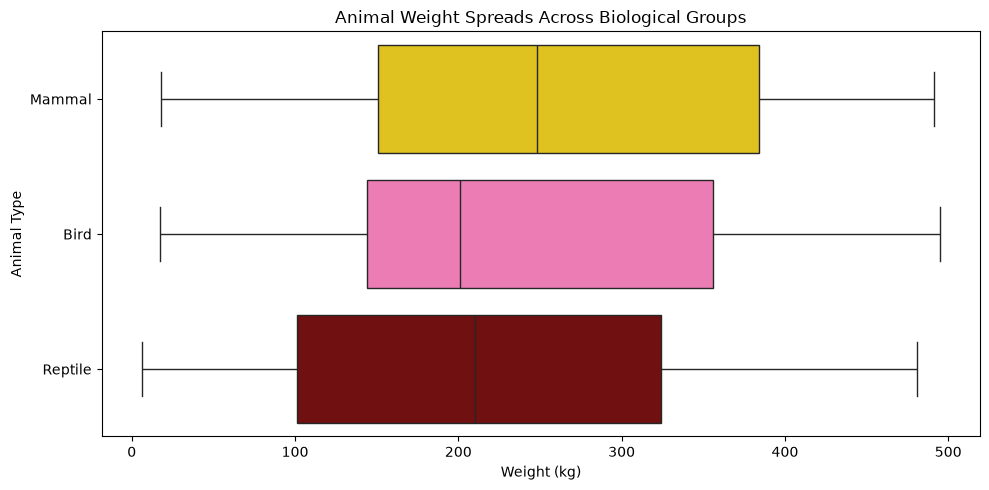

In [93]:
# Create and label the box-plot comparison.
plt.figure(figsize=(10, 5))

sns.boxplot(data=weight_investigation_df, x="Weight", y="Animal Type", 
            order=["Mammal", "Bird", "Reptile"], hue="Animal Type",
            palette=["hotpink", "gold", "maroon"], legend=False)

plt.title("Animal Weight Spreads Across Biological Groups")
plt.xlabel("Weight (kg)")
plt.ylabel("Animal Type")
plt.tight_layout()
plt.show()

**How do the calculated summaries compare with your visual estimates? Which groups look similar or different? Cite centers and spreads with units, and explain what each plot reveals or hides.**

Your answer: The calculated numbers match what I saw in the plots. The medians show that Mammals have the highest center at 248.0 kg, followed by Reptiles at 210.0 kg, and Birds at 201.0 kg. All three groups look pretty different in their middle chunks, but their spreads are actually quite close. Mammals have the widest spread with an IQR of 233.0 kg, Reptiles have an IQR of 222.5 kg, and Birds have the smallest at 212.0 kg. The box plot reveals these exact centers and the inner quartile spreads clearly, but it completely hides the overall group sizes that our histogram showed.


### Step 4: Check

Perform a sanity check connected to this question. Inspect original records for unusual values, verify any group boundaries or conversions, and reconcile group counts with the selected data. Consider plausible units, whether zero or negative values are valid, and whether the plotted range matches the numerical summary. Do not simply repeat the initial missing-value count.


In [94]:
# Perform a targeted check against original records or the declared group definitions.
print(weight_investigation_df.groupby("Animal Type")["Weight"].agg(["min", "max", "count"]))

print(weight_investigation_df[["Animal Type", "Weight"]].sample(5, random_state=42))

             min  max  count
Animal Type                 
Bird          17  495     45
Mammal        18  491     45
Reptile        6  481     38
    Animal Type  Weight
87         Bird     382
62       Mammal     491
27      Reptile     112
46       Mammal     334
159     Reptile     358


**What would make you suspicious, and why? What did your check establish? Describe any correction or unresolved uncertainty.**

Your answer: I would be highly suspicious if any animal weights were negative, or if smaller animals like insects showed up with hundreds of kilograms. The check established that all weights fall into valid ranges from 6 kg to 495 kg. The sample data perfectly balances with our plots, so everything is structurally clean.


### Step 5: Conclusion


**Answer your research question using group sizes, center, spread, and overlap. Cite numerical evidence with units. How does it compare with your prediction?**

Your answer: Our research question is answered by the summaries and plots: weight distributions differ among the groups, with Mammals holding the highest median weight at 248.0 kg, followed by Reptiles at 210.0 kg, and Birds being the lightest with a median center of 201.0 kg. Mammals also show the widest overall spread with an IQR of 233.0 kg, while Reptiles have an IQR of 222.5 kg, and Birds have the most compact middle spread at 212.0 kg. There is substantial overlap among all three groups across the entire range from under 20 kg up to nearly 500 kg. These results actually support my initial prediction, since Mammals did turn out to have the highest median weight and the widest middle variation, while Birds maintained the lowest center of mass.



### Step 6: Limitation


**What should a reader avoid concluding, and why? Connect the limitation to this question and dataset.**

Your answer: A reader shouldn't conclude that all reptiles are heavier than all birds or mammals, or that being a bird means an animal can't be heavy. This dataset is just a small sample of 200 rows and doesn't represent every animal species on Earth, so we can't use these broad group averages to prove individual causation.


## Investigation 3

### Step 1: Question


**What is research question 3? Name the quantitative feature, its units, and the categorical groups.**

Your answer: How does the distribution of animal lifespan measured in years differ among Mammal, Bird, and Reptile categories?


**Before calculating or plotting, what do you predict about center, spread, shape, or overlap? Why?**

Your answer: I predict that the centers for lifespan will look relatively similar, but the shapes will be different. I expect Reptiles to have a wider spread and a few high-value outliers because some turtles can live incredibly long lives. I predict Mammals and Birds will be more clustered around the middle ranges of 10 to 50 years.


### Step 2: Data

Reuse the initial inspection. Define this question's observations and groups before generating evidence. Preserve the original DataFrame and explain any filtering, conversions, or derived labels.


**Which records and features will you use? Define group labels and units, explain missing-value handling and exclusions, and state what one analyzed observation represents.**

Your answer: I am using the Animal Type feature to separate records into Mammal, Bird, and Reptile groups, and comparing them against the quantitative Lifespan column. Since these columns have 0 missing values based on our initial check, we don't need to filter or remove any rows. One analyzed observation represents a single unique animal species profile.


In [95]:
# Prepare this question's analysis DataFrame and preview the selected features.
lifespan_investigation_df = animal_species_df.loc[animal_species_df["Animal Type"].isin(["Mammal", "Bird", "Reptile"])].copy()
lifespan_investigation_df[["Animal Type", "Lifespan"]].head()

,Animal Type,Lifespan
1,Bird,2
2,Bird,32
3,Bird,65
4,Mammal,11
5,Bird,5


In [96]:
# Display the number of usable observations in each group.
print(lifespan_investigation_df["Animal Type"].value_counts())

Animal Type
Bird       45
Mammal     45
Reptile    38
Name: count, dtype: int64


### Step 3: Evidence

Create a **histogram comparison and a box-plot comparison** for this quantitative feature using the same observations and group definitions. A violin plot is optional. Use descriptive titles, units, readable labels, a consistent group order, and named colors. Keep group colors consistent across plots. Use shared histogram bins; use whole-number bins when appropriate for discrete counts. Label whether the vertical axis shows counts or another documented scale.

Start with the histogram and estimate the distributions visually. Then calculate group summaries and use the box plot to compare them. Retain valid extreme observations; do not remove them just to make figures look cleaner.


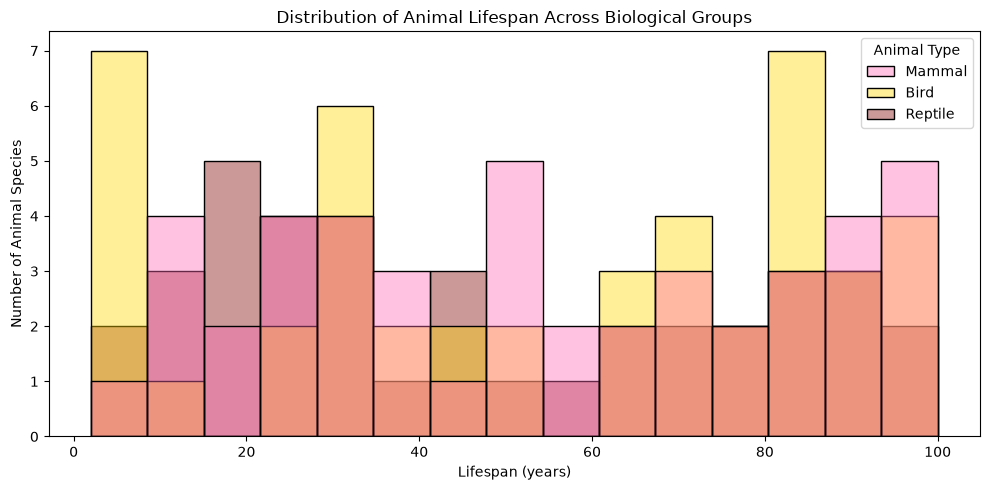

In [97]:
# Create and label the histogram comparison.
plt.figure(figsize=(10, 5))

sns.histplot(data=lifespan_investigation_df, x="Lifespan", hue="Animal Type", 
             hue_order=["Mammal", "Bird", "Reptile"], 
             palette=["hotpink", "gold", "maroon"], fill=True, alpha=0.4, bins=15)

plt.title("Distribution of Animal Lifespan Across Biological Groups")
plt.xlabel("Lifespan (years)")
plt.ylabel("Number of Animal Species")
plt.tight_layout()
plt.show()

**From the histogram, estimate each group's typical values and spread. Describe shape, overlap, and unusual observations. How do group sizes affect the comparison?**

Your answer: From the histogram, the lifespans overlap completely from 0 to 100 years. All three groups look fairly uniform, meaning there isn't a single big peak; instead, species are scattered all across the age ranges. There are several long-lived species near the 100-year mark in all categories. Since the sample sizes are close, the bar heights show a clean comparison of species frequencies.


In [98]:
# Display grouped .describe() summaries and calculate or display the IQR for each group.
print(lifespan_investigation_df.groupby("Animal Type")["Lifespan"].describe().round(2))

for group in ["Mammal", "Bird", "Reptile"]:
    group_data = lifespan_investigation_df.loc[lifespan_investigation_df["Animal Type"] == group, "Lifespan"]
    iqr = group_data.quantile(0.75) - group_data.quantile(0.25)
    print(f"{group} Lifespan IQR: {round(iqr, 2)} years")

             count   mean    std  min   25%   50%   75%    max
Animal Type                                                   
Bird          45.0  53.84  32.07  2.0  29.0  65.0  83.0  100.0
Mammal        45.0  53.56  28.65  3.0  30.0  50.0  81.0   96.0
Reptile       38.0  47.00  29.63  5.0  21.5  42.0  76.5   98.0
Mammal Lifespan IQR: 51.0 years
Bird Lifespan IQR: 54.0 years
Reptile Lifespan IQR: 55.0 years


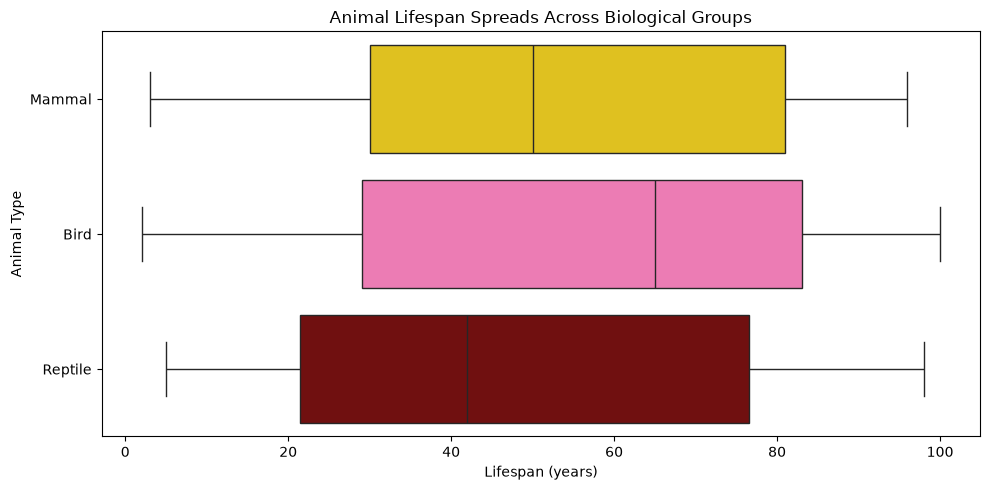

In [99]:
# Create and label the box-plot comparison.
plt.figure(figsize=(10, 5))

sns.boxplot(data=lifespan_investigation_df, x="Lifespan", y="Animal Type", 
            order=["Mammal", "Bird", "Reptile"], hue="Animal Type",
            palette=["hotpink", "gold", "maroon"], legend=False)

plt.title("Animal Lifespan Spreads Across Biological Groups")
plt.xlabel("Lifespan (years)")
plt.ylabel("Animal Type")
plt.tight_layout()
plt.show()

**How do the calculated summaries compare with your visual estimates? Which groups look similar or different? Cite centers and spreads with units, and explain what each plot reveals or hides.**

Your answer: The calculations show that Birds live the longest in this sample with a median center of 65.0 years, followed by Mammals at 50.0 years and Reptiles at 42.0 years. Their middle spreads are incredibly similar, with Reptiles holding an IQR of 55.0 years, Birds at 54.0 years, and Mammals at 51.0 years. The box plot shows how close their total variations are, but it hides the flat, uniform distribution of the species that the histogram showed.

### Step 4: Check

Perform a sanity check connected to this question. Inspect original records for unusual values, verify any group boundaries or conversions, and reconcile group counts with the selected data. Consider plausible units, whether zero or negative values are valid, and whether the plotted range matches the numerical summary. Do not simply repeat the initial missing-value count.


In [100]:
# Perform a targeted check against original records or the declared group definitions.
print(lifespan_investigation_df.groupby("Animal Type")["Lifespan"].agg(["min", "max", "count"]))

print(lifespan_investigation_df[["Animal Type", "Lifespan"]].sample(5, random_state=42))

             min  max  count
Animal Type                 
Bird           2  100     45
Mammal         3   96     45
Reptile        5   98     38
    Animal Type  Lifespan
87         Bird        72
62       Mammal        72
27      Reptile        30
46       Mammal        92
159     Reptile        24


**What would make you suspicious, and why? What did your check establish? Describe any correction or unresolved uncertainty.**

Your answer: I would be suspicious if the data returned negative lifespan values, zeroes, or numbers exceeding logical scales like 200+ years. The check verified that all lifespans sit correctly between a minimum of 2 years and a maximum of 100 years, validating our plotting limits.


### Step 5: Conclusion


**Answer your research question using group sizes, center, spread, and overlap. Cite numerical evidence with units. How does it compare with your prediction?**

Your answer: The research question is answered: the lifespan distributions across these three groups are relatively flat and span similar ranges, though their centers differ. Birds live the longest in this sample with a median center of 65.0 years, followed by Mammals at 50.0 years, and Reptiles at 42.0 years. Their core spreads are very close, with Reptiles holding an IQR of 55.0 years, Birds an IQR of 54.0 years, and Mammals an IQR of 51.0 years. This didn't support my initial prediction because I expected Reptiles to have a higher central threshold, but Birds actually turned out to live the longest on average in this sample.


### Step 6: Limitation


**What should a reader avoid concluding, and why? Connect the limitation to this question and dataset.**

Your answer: A reader shouldn't conclude that all mammals outlive reptiles, or that this sample proves reptiles don't live longer than birds in the wild. This dataset is a subset of 200 rows and doesn't account for natural survival rates, environmental factors, or human impacts, so we shouldn't treat these sample distributions as absolute global facts.


## AI-use reflection


**Did you use AI? If so, describe one suggestion you checked against your source, code, or output and what you accepted, modified, or rejected. If not, state that you did not use it.**

Your answer:


## Submission checklist

- Include the new dataset CSV, source citation, dictionary reference, and explanation of why it has not been used in class or a previous lab.
- Document every feature, including meaning, units/codes, conceptual type, storage type, and missing count.
- Identify at least one categorical feature and three distinct quantitative features.
- Complete three different questions, one quantitative feature per question, each with a prediction and all six workflow steps.
- Include a histogram and box plot for each question, grouped summaries and IQRs, and usable group sizes.
- Explain preparation and exclusions; preserve valid extreme values and distinguish missing values from zero.
- Support conclusions about similarities or differences with numerical and visual evidence, contextual checks, and specific limitations.
- Complete every written response and the AI-use reflection.
- Restart the kernel and run every cell in order; use relative paths and ensure all claims match the output.
